# Факторный анализ в Python

**Дисциплина:** Введение в анализ больших данных

**Факторный анализ** снижает размерность: много наблюдаемых переменных объясняются меньшим числом **латентных факторов**.

- **нагрузки (loadings)** — связь переменных с факторами;
- **общность (communality)** — доля дисперсии, объяснённая факторами;
- **собственные значения** — вклад факторов;
- **вращение (varimax)** — для интерпретируемости.

Инструменты: `sklearn.decomposition.FactorAnalysis`, собственные значения / scree, varimax.

Демо: синтетический опрос о качестве сервиса.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import FactorAnalysis
from sklearn.preprocessing import StandardScaler

plt.rcParams["figure.figsize"] = (10, 6)
sns.set_style("whitegrid")
np.random.seed(7)


---
## 1. Данные

Девять пунктов шкалы 1–5. Заложены три латентных фактора:  
«качество», «доставка», «поддержка».


In [7]:
df = pd.read_csv('FactorAn.csv', sep=';')
df = df.apply(lambda x: x.str.replace(',', '.')).astype(float)
print(df.info())
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   WORK_1     100 non-null    float64
 1   WORK_2     100 non-null    float64
 2   WORK_3     100 non-null    float64
 3   HOBBY_1    100 non-null    float64
 4   HOBBY_2    100 non-null    float64
 5   HOME_1     100 non-null    float64
 6   HOME_2     100 non-null    float64
 7   HOME_3     100 non-null    float64
 8   MISCEL_1   100 non-null    float64
 9   MISCEL_2   100 non-null    float64
dtypes: float64(10)
memory usage: 7.9 KB
None


,WORK_1,WORK_2,WORK_3,HOBBY_1,HOBBY_2,HOME_1,HOME_2,HOME_3,MISCEL_1,MISCEL_2
0,105.126,101.659,115.060,100.998,95.184,100.281,101.667,85.553,104.035,110.278
1,77.049,72.933,77.485,72.744,61.563,93.854,95.392,88.609,70.115,72.000
2,86.017,82.206,78.889,77.951,91.705,86.773,108.070,93.348,86.021,70.688
3,91.425,106.107,95.640,90.901,111.466,100.248,86.080,93.822,101.224,82.665
4,113.714,92.029,99.079,79.277,98.416,104.013,83.271,69.621,82.820,70.022


### Корреляционная матрица


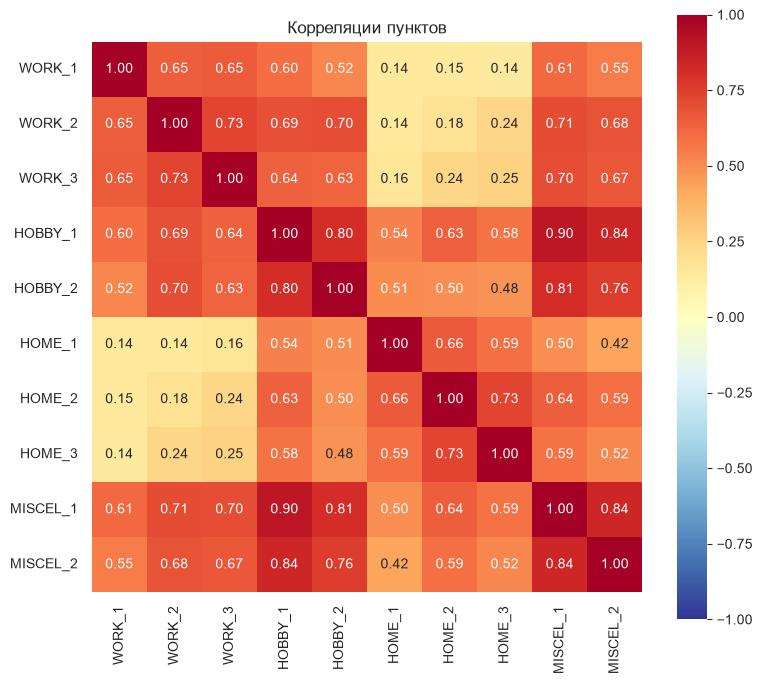

In [8]:
corr = df.corr()
plt.figure(figsize=(8, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdYlBu_r", center=0,
            vmin=-1, vmax=1, square=True)
plt.title("Корреляции пунктов")
plt.tight_layout()
plt.show()


In [12]:
upper_triangle = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

corr_pairs = upper_triangle.stack().reset_index()
corr_pairs.columns = ['Переменная 1', 'Переменная 2', 'Корреляция']

top_10_corr = corr_pairs.sort_values(by='Корреляция', ascending=False).head(10)
top_10_corr.style.background_gradient(cmap='Blues', subset=['Корреляция'])

,Переменная 1,Переменная 2,Корреляция
38,HOBBY_1,MISCEL_1,0.904469
39,HOBBY_1,MISCEL_2,0.843201
89,MISCEL_1,MISCEL_2,0.841425
48,HOBBY_2,MISCEL_1,0.811006
34,HOBBY_1,HOBBY_2,0.804693
49,HOBBY_2,MISCEL_2,0.755766
12,WORK_2,WORK_3,0.731895
67,HOME_2,HOME_3,0.730643
18,WORK_2,MISCEL_1,0.708628
28,WORK_3,MISCEL_1,0.697891


### Выводы

**WORK_1-3:**
> Переменные имеют положительные корреляции между собой (0.65-0.73).
>
> Скорее всего, три пункта опросника измеряют единый скрытый фактор - **удовлетворённость работой**.

**HOBBY_1-2:**
> Хобби тоже коррелируют между собой - 0.80. Наверное, это **удовлетворённость по хобби**

**HOME_1-3:**
> Корреляции внутри блока составляют 0.59–0.73, что также указывает на наличие общего фактора **домашней удовлетворённости**.

**MISCEL_1-2:**
> Самая тесная связь между факторами этого класса - 0.84. Тут не совсем понятно что за фактор, наверное от слово miscellaneous и сокращения MISC, что означает **разное/смешанное**

**Межклассовые связи:**
> Особый интерес представляет высокая корреляция между блоками HOBBY_1 и MISCEL_1-2 (значения 0.81–0.90). Скорее всего, при факторном анализе, эти факторы можно объединить - возможно, **удовлетворённость досугом и прочими сферами жизни**.
>
> Также интересен фактор HOME, который почти не коррелирует с WORK, а с остальным средне. Наибольший показатель внутри класса, то есть можно выделить один сильный фактор **домашний уют**.


---
## 2. Число факторов: scree и parallel analysis

Критерий Кайзера: собственные значения > 1.  
Parallel analysis: сравниваем с собственными значениями случайных данных.


Собственные значения: [6.118 1.801 0.473 0.408 0.317 0.293 0.196 0.17  0.138 0.085]


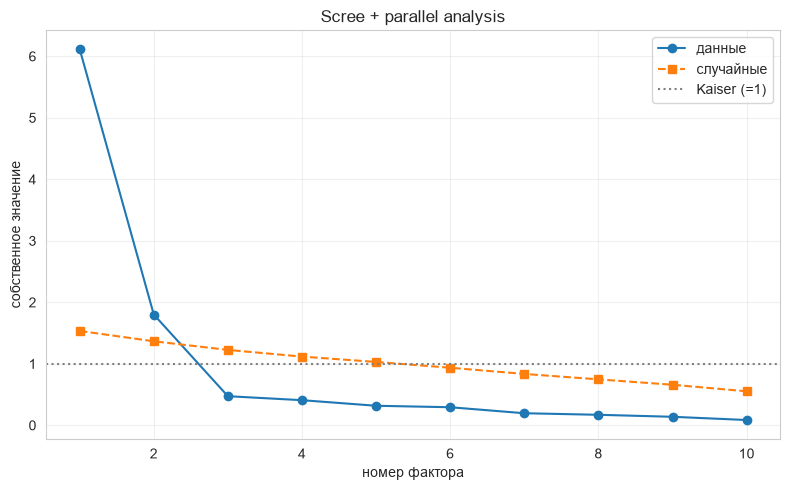

По parallel analysis (eig > random): 2


In [19]:
eigvals = np.linalg.eigvalsh(corr.values)[::-1]
print("Собственные значения:", np.round(eigvals, 3))

n_perm = 40
rand_eigs = []
for _ in range(n_perm):
    R = StandardScaler().fit_transform(np.random.normal(size=df.shape))
    C = np.corrcoef(R.T)
    rand_eigs.append(np.linalg.eigvalsh(C)[::-1])
rand_eigs = np.mean(rand_eigs, axis=0)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(eigvals)+1), eigvals, "o-", label="данные")
plt.plot(range(1, len(rand_eigs)+1), rand_eigs, "s--", label="случайные")
plt.axhline(1, color="gray", ls=":", label="Kaiser (=1)")
plt.xlabel("номер фактора")
plt.ylabel("собственное значение")
plt.title("Scree + parallel analysis")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("По parallel analysis (eig > random):", int(np.sum(eigvals > rand_eigs)))


### Вывод

Что первое бросается в глаза, так это схожесть с графиками локтя.

И тут почти такой же принцип, смотрим до излома, только ещё **собственные значения > 1**.

У нас получается **2 фактора по графику, 2 по параллельному анализу**
(Сам PA показывает разницу между случайными данными и фактическими, по сути мы отсекаем шум шумом)



---
## 3. Оценка факторной модели

`FactorAnalysis` + вращение **varimax**.


In [24]:
def varimax(Phi, gamma=1.0, q=30, tol=1e-6):
    p, k = Phi.shape
    R = np.eye(k)
    d = 0.0
    for _ in range(q):
        d_old = d
        Lambda = Phi @ R
        u, s, vh = np.linalg.svd(
            Phi.T @ (Lambda**3 - (gamma / p) * Lambda @ np.diag(np.diag(Lambda.T @ Lambda)))
        )
        R = u @ vh
        d = float(np.sum(s))
        if d_old and d / d_old < 1 + tol:
            break
    return Phi @ R

def fit_fa(data, n_factors):
    scaler = StandardScaler()
    data_scaled = scaler.fit_transform(data)

    fa = FactorAnalysis(n_components=n_factors, random_state=0, max_iter=2000)
    fa.fit(data_scaled)

    loadings = varimax(fa.components_.T)

    df = pd.DataFrame(
        loadings, index=data.columns,
        columns=[f"F{i+1}" for i in range(n_factors)],
    )
    df["communality"] = (loadings ** 2).sum(axis=1)
    return df, fa


In [25]:
print("=== 2 фактора ===")
load2, _ = fit_fa(df, 2)
print(load2.round(3))

print("\n=== 3 фактора ===")
load3, _ = fit_fa(df, 3)
print(load3.round(3))


=== 2 фактора ===
              F1     F2  communality
WORK_1     0.756 -0.024        0.573
WORK_2     0.889 -0.044        0.792
WORK_3     0.817 -0.099        0.677
HOBBY_1    0.748 -0.574        0.888
HOBBY_2    0.733 -0.439        0.730
HOME_1     0.142 -0.717        0.534
HOME_2     0.168 -0.901        0.840
HOME_3     0.201 -0.766        0.627
MISCEL_1   0.775 -0.562        0.916
MISCEL_2   0.736 -0.499        0.791

=== 3 фактора ===
              F1     F2     F3  communality
WORK_1     0.754 -0.024  0.027        0.570
WORK_2     0.886 -0.034 -0.070        0.791
WORK_3     0.821 -0.100  0.057        0.688
HOBBY_1    0.750 -0.558 -0.111        0.886
HOBBY_2    0.732 -0.410 -0.322        0.807
HOME_1     0.126 -0.702 -0.382        0.655
HOME_2     0.173 -0.921  0.030        0.878
HOME_3     0.209 -0.754 -0.079        0.618
MISCEL_1   0.781 -0.553 -0.039        0.917
MISCEL_2   0.744 -0.495  0.002        0.798


### Вывод
**2F:**
> Явно выделяется 2 фактора, это "досуг/работа" - полож. и "домашний уют" - отриц.
>
> У всех факторов довольно высокие показатели communality, но выделяется MISCEL_1, HOBBY_1, HOME_2.

**3F:**
> Также прошлые 2 фактора, но третий не особо выделяется, а учитывая порог 0.4 нагрузки, то 3 фактор вообще не нужен.

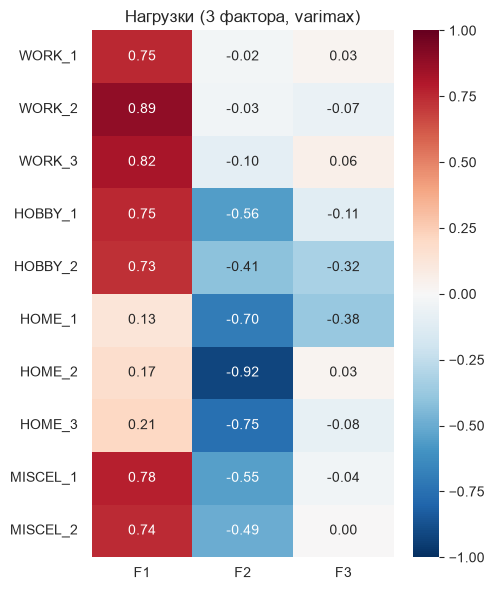

In [26]:
plt.figure(figsize=(5, 6))
sns.heatmap(load3.drop(columns=["communality"]), annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Нагрузки (3 фактора, varimax)")
plt.tight_layout()
plt.show()


### Как читать нагрузки

- |нагрузка| ≳ 0.4–0.5 → переменная связана с фактором;  
- высокая **communality** → пункт хорошо объясняется факторами;  
- дайте факторам **содержательные** имена по сильным нагрузкам.


---
## 4. KMO (пригодность данных для FA)

Желательно KMO > 0.6.


In [27]:
def kmo_simple(corr):
    C = np.asarray(corr, float).copy()
    inv = np.linalg.inv(C)
    pcorr = -inv / np.sqrt(np.outer(np.diag(inv), np.diag(inv)))
    np.fill_diagonal(pcorr, 0)
    np.fill_diagonal(C, 0)
    r2 = (C ** 2).sum()
    p2 = (pcorr ** 2).sum()
    return r2 / (r2 + p2)

print(f"KMO ≈ {kmo_simple(corr.values):.3f}")


KMO ≈ 0.915


### Как описать результаты

1. Корреляции и KMO — уместен ли FA.  
2. Scree / parallel — сколько факторов.  
3. Таблица нагрузок после varimax — интерпретация и имена факторов.  
4. Communality — насколько хорошо каждый пункт объясняется.

---
## Шпаргалка по методам (Python)

| Задача | Код |
|--------|-----|
| Корреляции | `df.corr()` |
| Собственные значения | `np.linalg.eigvalsh(corr)[::-1]` |
| FA | `FactorAnalysis(n_components=k).fit(X)` |
| Нагрузки | `fa.components_.T` (+ varimax) |
| Communality | `(loadings**2).sum(axis=1)` |

---
## Что сделать после лекции

1. Откройте лабораторное задание и выполните FA **самостоятельно** на своём CSV.  
2. Число факторов выбирайте и по числам, и по интерпретируемости.

Удачи!
